# Exploring the Lorenz parameter space (Strogatz §9.5)

**Author:** Julien Emile-Geay
**Date:** last-modified

_Description:_ Reproduction of the figures of Section 9.5 ("Exploring Parameter Space") of Strogatz, *Nonlinear Dynamics and Chaos* (2nd ed.), with the `Lorenz63` critter: bifurcation diagram for small $r$, homoclinic explosion, transient chaos, and the large-$r$ limit cycle.

_Abstract_

> Strogatz's Section 9.5 takes a walk through the parameter space of the Lorenz equations, holding $\sigma=10$, $b=8/3$ and varying the Rayleigh number $r$. This notebook rebuilds its five figures from simulations. Figure 9.5.1 is a schematic in the book. Here it is computed: the fixed-point branches and their stability come from the Jacobian, and the unstable limit cycles born in the homoclinic bifurcation at $r\approx13.926$ are found by Newton shooting and continued up to the subcritical Hopf point $r_H\approx24.74$. Figures 9.5.2–9.5.3 show *transient chaos* at $r=21$: a trajectory that wanders over a ghost of the strange attractor before settling on $C^+$. Figures 9.5.4–9.5.5 show that the dynamics become simple again at large $r$: at $r=350$ every trajectory converges to a single, symmetric limit cycle.

**Keywords:** Lorenz63, bifurcation diagram, homoclinic bifurcation, subcritical Hopf, unstable limit cycle, shooting method, transient chaos, metastable chaos, limit cycle, Strogatz

## Overview

The Lorenz equations, in Strogatz's notation, are

$$\dot x = \sigma(y-x), \qquad \dot y = rx - y - xz, \qquad \dot z = xy - bz .$$

The `Lorenz63` critter uses the same equations with `sigma` $=\sigma$, `rho` $=r$ and `beta` $=b$. Throughout we keep the defaults `sigma=10`, `beta=8/3`, and vary `rho`.

| Book figure | Content | Section below |
|---|---|---|
| 9.5.1 | Bifurcation diagram for $0 < r < r_H$ | [Small r: bifurcation diagram](#small-r) |
| 9.5.2 | Transient chaos at $r=21$, $(x,z)$ projection | [Transient chaos](#transient) |
| 9.5.3 | Transient chaos at $r=21$, $y(t)$ | [Transient chaos](#transient) |
| 9.5.4 | Approach to the limit cycle at $r=350$, $(x,z)$ projection | [Large r](#large-r) |
| 9.5.5 | Approach to the limit cycle at $r=350$, $y(t)$ | [Large r](#large-r) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

import climatecritters as cc
from climatecritters.model_critters.lorenz import Lorenz63

sigma, b = 10.0, 8 / 3     # held fixed throughout Section 9.5

<a id="small-r"></a>
## Small r: bifurcation diagram (Figure 9.5.1)

The book draws Figure 9.5.1 as a schematic. We compute each of its ingredients.

**Fixed points.** The origin exists for all $r$. For $r>1$ a symmetric pair appears,
$C^\pm = \left(\pm\sqrt{b(r-1)},\ \pm\sqrt{b(r-1)},\ r-1\right)$. Their stability follows from the eigenvalues of the Jacobian
$$
J = \begin{pmatrix} -\sigma & \sigma & 0 \\ r - z & -1 & -x \\ y & x & -b \end{pmatrix}.
$$
$C^\pm$ lose stability in a subcritical Hopf bifurcation at
$r_H = \sigma(\sigma+b+3)/(\sigma-b-1)$.

In [2]:
def jacobian(x, y, z, r):
    return np.array([[-sigma, sigma, 0.0],
                     [r - z, -1.0, -x],
                     [y, x, -b]])

def max_real_eig(point, r):
    return np.linalg.eigvals(jacobian(*point, r)).real.max()

r_H = sigma * (sigma + b + 3) / (sigma - b - 1)
r_grid = np.linspace(0, 28, 1401)

origin_stable = np.array([max_real_eig((0, 0, 0), r) < 0 for r in r_grid])
r_C = r_grid[r_grid > 1]
x_C = np.sqrt(b * (r_C - 1))
C_stable = np.array([max_real_eig((xc, xc, r - 1), r) < 0 for xc, r in zip(x_C, r_C)])

print(f"Analytic Hopf point            r_H = {r_H:.4f}")
print(f"Numerical loss of C+ stability r   = {r_C[~C_stable][0]:.2f}")
print(f"Numerical loss of 0 stability  r   = {r_grid[~origin_stable][0]:.2f}")

Analytic Hopf point            r_H = 24.7368
Numerical loss of C+ stability r   = 24.74
Numerical loss of 0 stability  r   = 1.00


**Unstable limit cycles.** The dashed branch in Figure 9.5.1 is a pair of unstable (saddle) limit cycles. They are born in the homoclinic bifurcation at $r\approx13.926$ and shrink onto $C^\pm$ at $r_H$. They repel trajectories, so forward integration can't find them. We locate them by **shooting**. On the plane $z=r-1$, which passes through $C^+$, we solve for a point $(x_0, y_0)$ and a period $T$ such that the flow map $\phi_T$ returns the trajectory to its starting point:

$$ \phi_T(x_0, y_0, r-1) - (x_0, y_0, r-1) = 0 .$$

We then follow the solution in $r$ by **numerical continuation**: each converged cycle, extrapolated linearly in $r$, seeds the next Newton solve.

Newton's method calls the flow map many times, once per Jacobian column at every iteration, so each evaluation must be cheap. The flow map below is the `Lorenz63` critter itself, integrated with SciPy's 8th-order `DOP853` scheme at tight tolerances. `integrate` forwards `method` and `kwargs` to `solve_ivp`. The full continuation (about 4000 integrations) takes roughly 15 s.

The `shoot` and `continue_cycle` functions below are prototypes of the general periodic-orbit and continuation utility proposed in [#52](https://github.com/LinkedEarth/ClimateCritters/issues/52).

In [3]:
def flow(p, T, r, output_time=None):
    """Flow map: integrate the Lorenz63 critter from p over a time T. Returns a cc Output."""
    model = Lorenz63(sigma=sigma, rho=r, beta=b)
    return model.integrate(t_span=(0, T), y0=p, method='DOP853', output_time=output_time,
                           kwargs={'rtol': 1e-12, 'atol': 1e-12})

def shoot(r, guess):
    """Newton solve for (x0, y0, T) of a periodic orbit through the plane z = r-1."""
    def residual(q):
        p0 = [q[0], q[1], r - 1]
        return flow(p0, q[2], r).solution.y[-1] - p0      # final state minus initial state
    q, info, ier, _ = fsolve(residual, guess, full_output=True, xtol=1e-12)
    return q, np.linalg.norm(info['fvec'])

def continue_cycle(r_values, q_start):
    """Natural-parameter continuation with a secant predictor."""
    rows, qs, rs = [], [], []
    for r in r_values:
        if len(qs) < 2:
            guess = qs[-1] if qs else q_start
        else:
            guess = qs[-1] + (qs[-1] - qs[-2]) * (r - rs[-1]) / (rs[-1] - rs[-2])
        q, res = shoot(r, guess)
        if res > 1e-8 or q[2] < 0.1:          # lost the branch
            break
        # one period of the converged cycle, sampled on 1000 points
        out = flow([q[0], q[1], r - 1], q[2], r, output_time=np.linspace(0, q[2], 1000))
        orbit = np.vstack([out.state_variables[v] for v in 'xyz'])
        rows.append(dict(r=r, q=q, T=q[2], xmin=orbit[0].min(), xmax=orbit[0].max(), orbit=orbit))
        qs.append(q); rs.append(r)
    return rows

# Starting guess at r = 20, obtained by bisecting for the boundary between initial
# conditions that spiral into C+ and those that escape to the other lobe
q20 = np.array([10.988, 14.279, 0.877])

up   = continue_cycle(np.arange(20.0, 24.73, 0.05), q20)       # toward the Hopf point
down = continue_cycle(np.arange(20.0, 14.15, -0.05), q20)      # toward the homoclinic orbit
cycles = sorted(down[1:] + up, key=lambda d: d['r'])
print(f"Cycle branch computed for {cycles[0]['r']:.2f} <= r <= {cycles[-1]['r']:.2f} "
      f"({len(cycles)} values of r)")
print(f"Period: T = {cycles[-1]['T']:.3f} near r_H,  T = {cycles[0]['T']:.3f} at r = {cycles[0]['r']:.2f}")

Cycle branch computed for 14.20 <= r <= 24.70 (211 values of r)
Period: T = 0.654 near r_H,  T = 2.073 at r = 14.20


Below $r\approx14.2$ the continuation stops converging. As $r\to13.926$ the cycle passes ever closer to the saddle at the origin, so its period diverges (logarithmically) and the shooting problem becomes badly conditioned. The trend toward the homoclinic orbit is already clear, though: $x_{\min}$ of the cycle tends to 0.

**Solver check.** The cycles were found with `DOP853`. As an independent check, we integrate one period of a few of them with a different scheme, the critter's default `RK45`, and measure how far each trajectory lands from its starting point. Because the cycles are unstable, the closure error grows with the period, but it stays small.

In [4]:
for d in cycles[::len(cycles) // 4]:
    r, (x0, y0, T) = d['r'], d['q']
    out = Lorenz63(sigma=sigma, rho=r, beta=b).integrate(
        t_span=(0, T), y0=[x0, y0, r - 1], method='RK45', kwargs={'rtol': 1e-12, 'atol': 1e-12})
    end = out.solution.y[-1]
    print(f"r = {r:6.2f}   T = {T:.4f}   |phi_T(p) - p| = {np.linalg.norm(end - [x0, y0, r - 1]):.1e}")

r =  14.20   T = 2.0729   |phi_T(p) - p| = 1.2e-07
r =  16.80   T = 1.1743   |phi_T(p) - p| = 5.5e-10
r =  19.40   T = 0.9179   |phi_T(p) - p| = 1.4e-10
r =  22.00   T = 0.7644   |phi_T(p) - p| = 4.5e-11
r =  24.60   T = 0.6576   |phi_T(p) - p| = 2.7e-11


Now assemble Figure 9.5.1. Solid lines mark stable states and dashed lines unstable ones. As in the book, only $C^+$ and its cycle are drawn; the $C^-$ branch is the mirror image under $x\mapsto -x$. The value $r\approx24.06$, where the transient chaos becomes a strange attractor, is taken from the literature (Kaplan & Yorke 1979; Yorke & Yorke 1979); it marks a global change in the dynamics that no local analysis can find. The right panel shows the cycles themselves in the $(x,z)$ plane. They grow from $C^+$ at $r_H$ until they touch the origin at the homoclinic bifurcation.

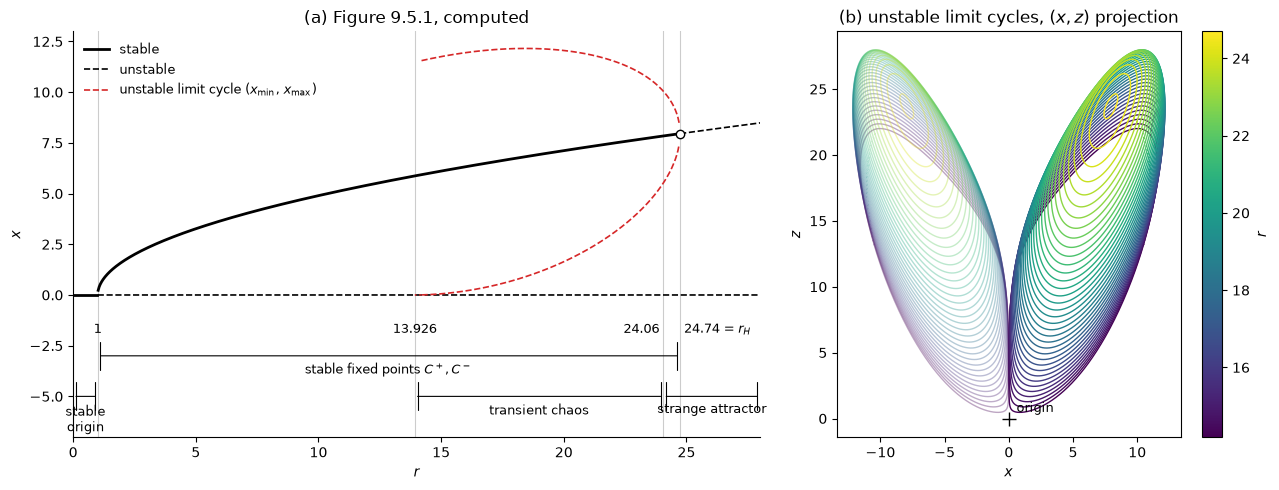

In [5]:
r_homoclinic, r_strange = 13.926, 24.06
r_cyc = np.array([d['r'] for d in cycles])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.6, 1]})

# --- (a) bifurcation diagram ---
ax.plot(r_grid[origin_stable], 0 * r_grid[origin_stable], 'k-', lw=2)
ax.plot(r_grid[~origin_stable], 0 * r_grid[~origin_stable], 'k--', lw=1.2)
ax.plot(r_C[C_stable], x_C[C_stable], 'k-', lw=2, label='stable')
ax.plot(r_C[~C_stable], x_C[~C_stable], 'k--', lw=1.2, label='unstable')
ax.plot(r_cyc, [d['xmax'] for d in cycles], '--', color='C3', lw=1.2,
        label='unstable limit cycle ($x_{\\min}$, $x_{\\max}$)')
ax.plot(r_cyc, [d['xmin'] for d in cycles], '--', color='C3', lw=1.2)
# x_min of the cycle reaches 0 at the homoclinic point (dotted: not computed)
ax.plot([r_homoclinic, r_cyc[0]], [0, cycles[0]['xmin']], ':', color='C3', lw=1.2)
ax.plot(r_H, np.sqrt(b * (r_H - 1)), 'o', mfc='white', mec='k', zorder=5)

for rv, lab, ha in [(1, '1', 'center'), (r_homoclinic, '13.926', 'center'),
                   (r_strange, '24.06 ', 'right'), (r_H, f' {r_H:.2f} = $r_H$', 'left')]:
    ax.axvline(rv, color='0.8', lw=0.8, zorder=0)
    ax.text(rv, -1.4, lab, ha=ha, va='top', fontsize=9)

# regime bars, as in the book
def bar(r0, r1, y, text):
    ax.annotate('', xy=(r0, y), xytext=(r1, y), arrowprops=dict(arrowstyle='|-|', lw=0.8))
    ax.text(0.5 * (r0 + r1), y - 0.35, text, ha='center', va='top', fontsize=9)
bar(0, 1, -5.0, 'stable\norigin')
bar(1, r_H, -3.0, 'stable fixed points $C^+, C^-$')
bar(r_homoclinic, r_strange, -5.0, 'transient chaos')
bar(r_strange, 28, -5.0, 'strange attractor')

ax.set_xlim(0, 28); ax.set_ylim(-7, 13)
ax.set_xlabel('$r$'); ax.set_ylabel('$x$')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.set_title('(a) Figure 9.5.1, computed')

# --- (b) the unstable cycles in phase space ---
cmap = plt.cm.viridis
for d in cycles[::6]:
    c = cmap((d['r'] - r_cyc.min()) / np.ptp(r_cyc))
    ax2.plot(d['orbit'][0], d['orbit'][2], color=c, lw=1)
    ax2.plot(-d['orbit'][0], d['orbit'][2], color=c, lw=1, alpha=0.35)   # symmetric partner around C-
ax2.plot(0, 0, 'k+', ms=10)
ax2.text(0.6, 0.5, 'origin', fontsize=9)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(r_cyc.min(), r_cyc.max()))
fig.colorbar(sm, ax=ax2, label='$r$')
ax2.set_xlabel('$x$'); ax2.set_ylabel('$z$')
ax2.set_title('(b) unstable limit cycles, $(x, z)$ projection')

plt.tight_layout(); plt.show()

**Figure 9.5.1 (computed).** (a) Bifurcation diagram for $0<r<28$, with $\sigma=10$, $b=8/3$. The origin loses stability in a supercritical pitchfork at $r=1$, which gives birth to $C^\pm$. The unstable limit cycle (red dashed; its maximum and minimum $x$ are shown) shrinks onto $C^+$ at the subcritical Hopf point $r_H\approx24.74$ (open circle), where $C^+$ becomes unstable. Moving down in $r$, the cycle grows until $x_{\min}\to0$: it touches the saddle at the origin and becomes a homoclinic orbit at $r\approx13.926$. The dotted segment marks the part of the branch, between $r=13.926$ and $r\approx14.2$, where the period diverges and shooting fails. (b) The cycles in the $(x,z)$ plane, colored by $r$, with their mirror images around $C^-$ drawn faintly. Note how close the outermost cycles come to the origin.

<a id="transient"></a>
## Transient chaos at r = 21 (Figures 9.5.2 and 9.5.3)

**Example 9.5.1.** For $13.926 < r < 24.06$, the homoclinic explosion leaves behind a non-attracting chaotic invariant set. Trajectories can wander near it for a long time before they escape to $C^+$ or $C^-$. At $r=21$ both fixed points are still stable. The initial condition below was picked, as the book suggests, "after experimenting with a few different initial conditions". It wanders for about 37 time units before spiraling into $C^+$.

In [6]:
r = 21
y0 = [20.0, -7.0, 9.0]
t_end = 70
t_out = np.linspace(0, t_end, 14001)

out21 = Lorenz63(rho=r).integrate(t_span=(0, t_end), y0=y0, output_time=t_out)
x21, y21, z21 = (out21.state_variables[v] for v in 'xyz')

xC = np.sqrt(b * (r - 1))
switch = np.where(np.diff(np.sign(x21)) != 0)[0]
print(f"C+ = ({xC:.3f}, {xC:.3f}, {r - 1})")
print(f"Last lobe switch at t = {t_out[switch[-1]]:.1f}; final state = "
      f"({x21[-1]:.3f}, {y21[-1]:.3f}, {z21[-1]:.3f})")

C+ = (7.303, 7.303, 20)
Last lobe switch at t = 36.6; final state = (7.469, 7.326, 20.389)


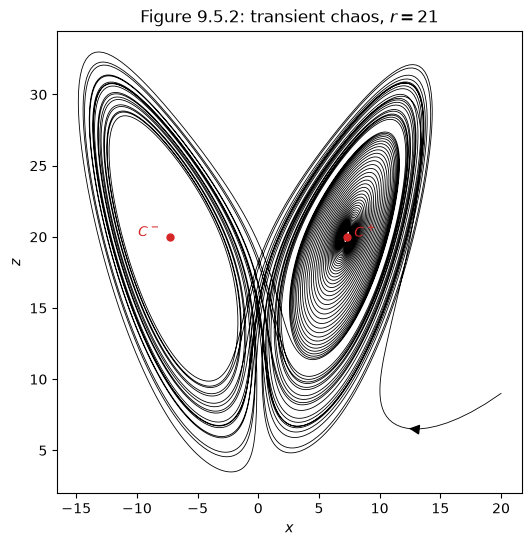

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x21, z21, lw=0.6, color='k')
k = 8     # arrowhead on the trajectory, pointing along the flow
ax.annotate('', xy=(x21[k + 1], z21[k + 1]), xytext=(x21[k], z21[k]),
            arrowprops=dict(arrowstyle='-|>', color='k', lw=1, mutation_scale=15))
ax.plot([xC, -xC], [r - 1, r - 1], 'o', color='C3', ms=5)
ax.text(xC + 0.6, r - 1, '$C^+$', color='C3'); ax.text(-xC - 2.6, r - 1, '$C^-$', color='C3')
ax.set_xlabel('$x$'); ax.set_ylabel('$z$')
ax.set_title(f'Figure 9.5.2: transient chaos, $r={r}$')
plt.show()

**Figure 9.5.2.** At first the trajectory seems to trace out a strange attractor, switching irregularly between the two lobes. Eventually it stays on the right and spirals in to the stable fixed point $C^+$ (red dot). The spiral is slow because $r=21$ is not far below $r_H$, where $C^+$ is only weakly stable.

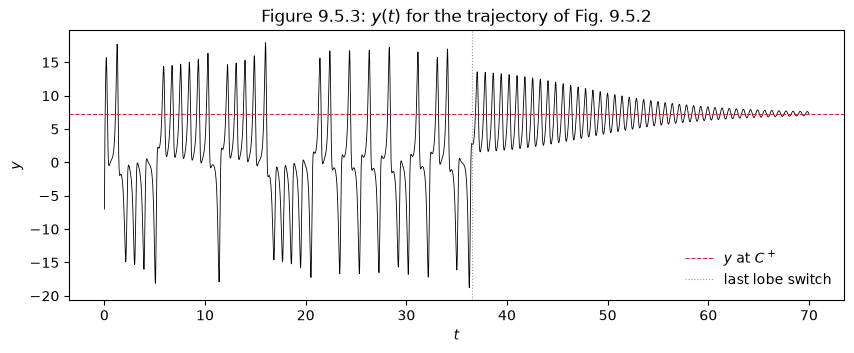

In [8]:
# Output.to_pyleo labels time as 'years CE' (pyleoclim's default; see #53). Lorenz time is
# dimensionless, so we set the axis label ourselves.
ts21 = out21.to_pyleo('y')
fig, ax = ts21.plot(figsize=(10, 3.5), color='k', linewidth=0.6, legend=False,
                    xlabel='$t$', ylabel='$y$',
                    title='Figure 9.5.3: $y(t)$ for the trajectory of Fig. 9.5.2')
ax.axhline(xC, color='C3', lw=0.8, ls='--', label='$y$ at $C^+$')
ax.axvline(t_out[switch[-1]], color='0.6', lw=0.8, ls=':', label='last lobe switch')
ax.legend(loc='lower right', frameon=False)
plt.show()

**Figure 9.5.3.** The time series tells the same story: an erratic solution that ultimately damps down to equilibrium. By Strogatz's definition this is not chaos, because the long-term behavior is not aperiodic. It still shows sensitive dependence on initial conditions, though. The initial condition $(20, -7, 7)$, a small step from the one used here, wanders for almost 80 time units and ends at $C^-$ instead.

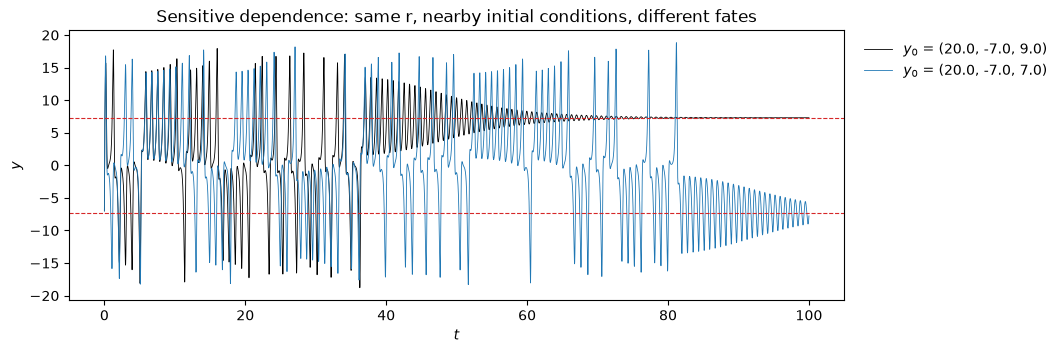

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.5))
t_long = np.linspace(0, 100, 20001)
for y0_, c in [([20.0, -7.0, 9.0], 'k'), ([20.0, -7.0, 7.0], 'C0')]:
    o = Lorenz63(rho=r).integrate(t_span=(0, 100), y0=y0_, output_time=t_long)
    o.to_pyleo('y').plot(ax=ax, color=c, linewidth=0.6, legend=False,
                         label=f'$y_0$ = {tuple(y0_)}', xlabel='$t$', ylabel='$y$')
ax.axhline(xC, color='C3', lw=0.8, ls='--'); ax.axhline(-xC, color='C3', lw=0.8, ls='--')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_title('Sensitive dependence: same r, nearby initial conditions, different fates')
plt.show()

<a id="large-r"></a>
## Large r: a globally attracting limit cycle (Figures 9.5.4 and 9.5.5)

**Example 9.5.2.** For $r > 313$, numerical simulations show a globally attracting limit cycle (Sparrow 1982). At $r=350$ we start near the now unstable fixed point $C^+$, and the trajectory spirals outward onto the cycle. In terms of the waterwheel of Section 9.1, the wheel ends up rocking back and forth like a pendulum, turning once to the right, then back to the left, and so on.

In [10]:
r = 350
xC = np.sqrt(b * (r - 1))
y0 = [30.0, 32.0, 380.0]
t_end = 5
t_out = np.linspace(0, t_end, 10001)

out350 = Lorenz63(rho=r).integrate(t_span=(0, t_end), y0=y0, output_time=t_out)
x350, y350, z350 = (out350.state_variables[v] for v in 'xyz')

print(f"C+ = ({xC:.2f}, {xC:.2f}, {r - 1})")

# Period of the limit cycle: the lag that best maps y(t) onto itself after the transient.
# (y crosses zero several times per period, so zero crossings would be ambiguous.)
late = t_out > 2
dt = t_out[1] - t_out[0]
lags = np.arange(int(0.2 / dt), int(2.0 / dt))
ys = y350[late]
mis = np.array([np.abs(ys[l:] - ys[:-l]).mean() for l in lags])
T350 = lags[np.argmin(mis)] * dt
print(f"Limit-cycle period at r = 350: T = {T350:.3f}")

C+ = (30.51, 30.51, 349)
Limit-cycle period at r = 350: T = 0.389


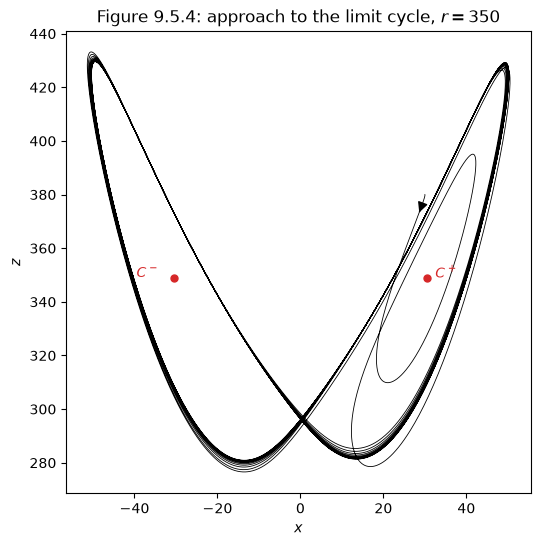

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x350, z350, lw=0.6, color='k')
k = 40    # arrowhead on the trajectory, pointing along the flow
ax.annotate('', xy=(x350[k + 1], z350[k + 1]), xytext=(x350[k], z350[k]),
            arrowprops=dict(arrowstyle='-|>', color='k', lw=1, mutation_scale=15))
ax.plot([xC, -xC], [r - 1, r - 1], 'o', color='C3', ms=5)
ax.text(xC + 2, r - 1, '$C^+$', color='C3'); ax.text(-xC - 9, r - 1, '$C^-$', color='C3')
ax.set_xlabel('$x$'); ax.set_ylabel('$z$')
ax.set_title(f'Figure 9.5.4: approach to the limit cycle, $r={r}$')
plt.show()

**Figure 9.5.4.** The trajectory leaves the unstable focus $C^+$ in growing loops and is captured by the limit cycle. The cycle visits both sides of the $z$-axis symmetrically, which corresponds to the waterwheel's back-and-forth rocking.

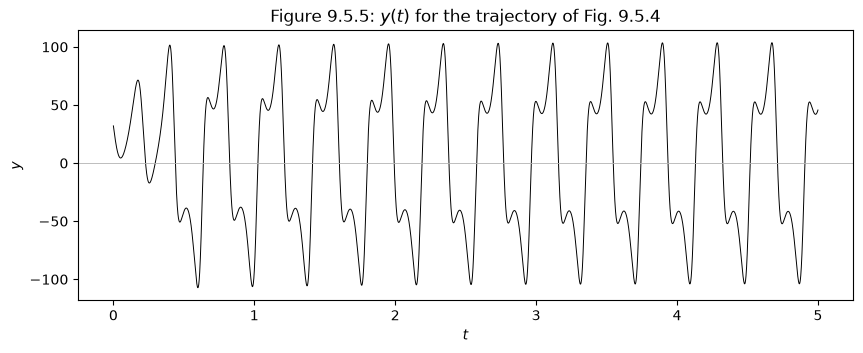

In [12]:
ts350 = out350.to_pyleo('y')      # time label overridden, as for Fig. 9.5.3
fig, ax = ts350.plot(figsize=(10, 3.5), color='k', linewidth=0.7, legend=False,
                     xlabel='$t$', ylabel='$y$',
                     title='Figure 9.5.5: $y(t)$ for the trajectory of Fig. 9.5.4')
ax.axhline(0, color='0.7', lw=0.6)
plt.show()

**Figure 9.5.5.** After a short transient of growing oscillations around $C^+$, $y(t)$ locks into a strictly periodic waveform with alternating positive and negative excursions.

## Beyond the figures

For $28 < r < 313$ the story is more complicated: chaos at most values of $r$, interrupted by windows of periodic behavior, the three largest being $99.524\ldots<r<100.795\ldots$, $145<r<166$ and $r>214.4$. Strogatz defers that discussion to the logistic map (Chapter 10). Another natural extension is Exercise 9.5.4: hysteresis between chaos and equilibrium for $24.06<r<24.74$, which could be explored by passing a slowly varying `cc.Forcing` as `rho`.

## References

- Kaplan, J. L., and J. A. Yorke, 1979: Preturbulence: A regime observed in a fluid flow model of Lorenz. *Commun. Math. Phys.*, 67, 93–108, [doi:10.1007/BF01221359](https://doi.org/10.1007/BF01221359).
- Lorenz, E. N., 1963: Deterministic nonperiodic flow. *J. Atmos. Sci.*, 20, 130–141, [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2).
- Sparrow, C., 1982: *The Lorenz Equations: Bifurcations, Chaos, and Strange Attractors*. Springer, [doi:10.1007/978-1-4612-5767-7](https://doi.org/10.1007/978-1-4612-5767-7).
- Strogatz, S. H., 2015: *Nonlinear Dynamics and Chaos*, 2nd ed. Westview Press, Section 9.5.
- Yorke, J. A., and E. D. Yorke, 1979: Metastable chaos: The transition to sustained chaotic behavior in the Lorenz model. *J. Stat. Phys.*, 21, 263–277, [doi:10.1007/BF01011469](https://doi.org/10.1007/BF01011469).